In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [2]:
# read the csv file
df = pd.read_csv(r"C:\Users\m_hossam\OneDrive\Desktop\data\mushrooms.csv")

# first 5 rows
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [3]:
# number of rows and columns
print("Shape:", df.shape)

Shape: (8124, 23)


In [4]:
# column names
print(df.columns.tolist())

['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']


In [5]:
# info about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

## 3. Exploratory Data Analysis (EDA)

In [6]:
print(df.isnull().sum())

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64


In [7]:
# hidden missing values written as "?"
question_marks = (df == "?").sum()
print(question_marks[question_marks > 0])

stalk-root    2480
dtype: int64


In [8]:
# duplicated rows
print("Duplicated rows:", df.duplicated().sum())

Duplicated rows: 0


class
e    4208
p    3916
Name: count, dtype: int64


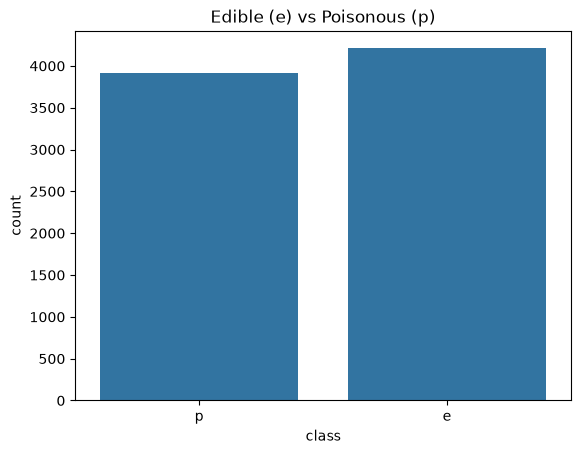

In [9]:
# target distribution
print(df["class"].value_counts())

sns.countplot(x="class", data=df)
plt.title("Edible (e) vs Poisonous (p)")
plt.show()

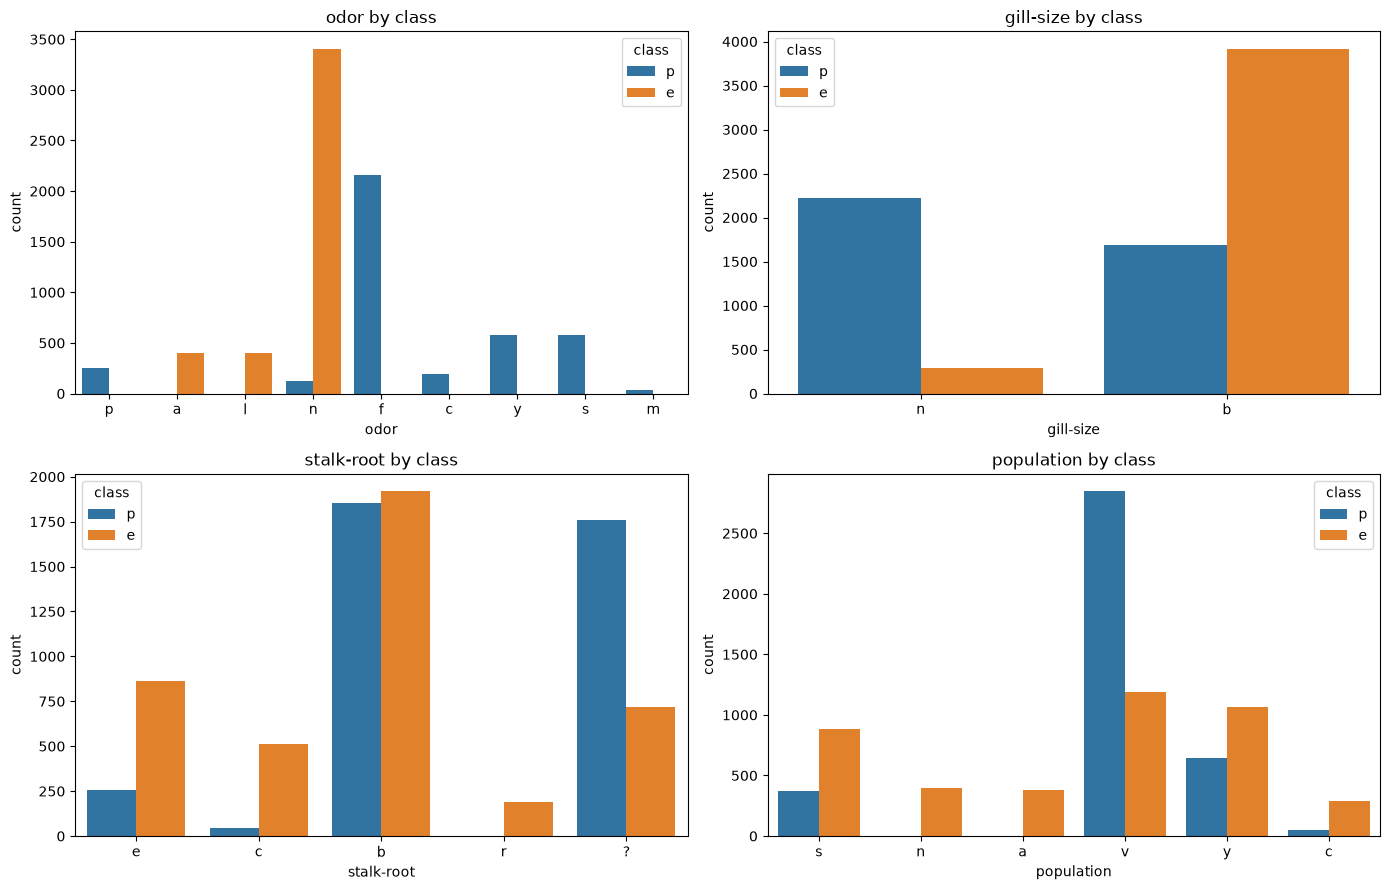

In [10]:
# some simple charts: important columns against the class
columns_to_plot = ["odor", "gill-size", "stalk-root", "population"]

plt.figure(figsize=(14, 9))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    sns.countplot(x=columns_to_plot[i], hue="class", data=df)
    plt.title(columns_to_plot[i] + " by class")
plt.tight_layout()
plt.show()

## 4. Data Preprocessing

In [11]:
# how many "?" in stalk-root
print("Before:", (df["stalk-root"] == "?").sum())

# keep them as a separate category called "missing"
df["stalk-root"] = df["stalk-root"].replace("?", "missing")

print("After:", (df["stalk-root"] == "?").sum())
print(df["stalk-root"].value_counts())

Before: 2480
After: 0
stalk-root
b          3776
missing    2480
e          1120
c           556
r           192
Name: count, dtype: int64


In [12]:
# find columns that have only one unique value
one_value_cols = []
for col in df.columns:
    if df[col].nunique() == 1:
        one_value_cols.append(col)

print("Columns with one value:", one_value_cols)

# remove them
df = df.drop(columns=one_value_cols)
print("New shape:", df.shape)


Columns with one value: ['veil-type']
New shape: (8124, 22)


In [13]:
# separate features (X) and target (y)
X = df.drop("class", axis=1)

# e = edible = 0 , p = poisonous = 1
y = df["class"].map({"e": 0, "p": 1})

print(y.value_counts())
print("Missing values in y:", y.isnull().sum())

class
0    4208
1    3916
Name: count, dtype: int64
Missing values in y: 0


In [14]:
# convert text columns to numbers (one-hot encoding)
X = pd.get_dummies(X)
X = X.astype(int)

print("Shape after encoding:", X.shape)
X.head()

Shape after encoding: (8124, 116)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


## 5. Split the Data

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (6499, 116)
Test shape: (1625, 116)


## 6. Decision Tree Model

In [16]:
# create and train the model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# predict on the test data
dt_pred = dt_model.predict(X_test)

print("Decision Tree accuracy:", accuracy_score(y_test, dt_pred))

Decision Tree accuracy: 1.0


## 7. Random Forest Model

In [17]:
# create and train the model (100 trees)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# predict on the test data
rf_pred = rf_model.predict(X_test)

print("Random Forest accuracy:", accuracy_score(y_test, rf_pred))

Random Forest accuracy: 1.0


## 8. Model Evaluation

In [18]:
# Decision Tree results
dt_acc = accuracy_score(y_test, dt_pred)
dt_prec = precision_score(y_test, dt_pred)
dt_rec = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)

print("Decision Tree")
print("Accuracy :", round(dt_acc, 4))
print("Precision:", round(dt_prec, 4))
print("Recall   :", round(dt_rec, 4))
print("F1-score :", round(dt_f1, 4))

Decision Tree
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0


In [19]:
# Random Forest results
rf_acc = accuracy_score(y_test, rf_pred)
rf_prec = precision_score(y_test, rf_pred)
rf_rec = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print("Random Forest")
print("Accuracy :", round(rf_acc, 4))
print("Precision:", round(rf_prec, 4))
print("Recall   :", round(rf_rec, 4))
print("F1-score :", round(rf_f1, 4))

Random Forest
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0


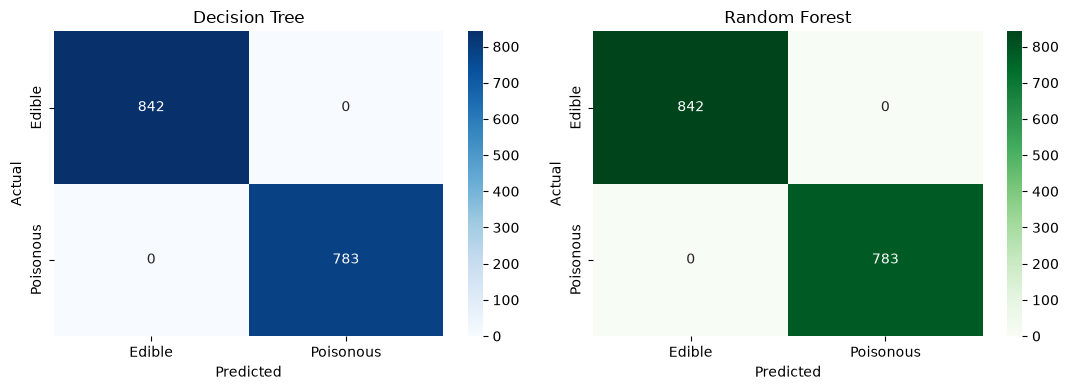

In [20]:
# confusion matrices
dt_cm = confusion_matrix(y_test, dt_pred)
rf_cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
sns.heatmap(dt_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Edible", "Poisonous"], yticklabels=["Edible", "Poisonous"])
plt.title("Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.subplot(1, 2, 2)
sns.heatmap(rf_cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Edible", "Poisonous"], yticklabels=["Edible", "Poisonous"])
plt.title("Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [21]:
# dangerous mistakes: poisonous mushrooms predicted as edible
print("Decision Tree - poisonous predicted as edible:", dt_cm[1][0])
print("Random Forest - poisonous predicted as edible:", rf_cm[1][0])

Decision Tree - poisonous predicted as edible: 0
Random Forest - poisonous predicted as edible: 0


## 9. Compare the Models

In [22]:
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [dt_acc, rf_acc],
    "Precision": [dt_prec, rf_prec],
    "Recall": [dt_rec, rf_rec],
    "F1-score": [dt_f1, rf_f1]})

comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,1.0,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0,1.0


In [23]:
# which model is better (using F1-score)
if rf_f1 > dt_f1:
    print("Random Forest has a higher F1-score.")
elif dt_f1 > rf_f1:
    print("Decision Tree has a higher F1-score.")
else:
    print("Both models have the same F1-score.")

if rf_rec > dt_rec:
    print("Random Forest has a higher Recall.")
elif dt_rec > rf_rec:
    print("Decision Tree has a higher Recall.")
else:
    print("Both models have the same Recall.")

Both models have the same F1-score.
Both models have the same Recall.


## 10. Feature Importance

odor_n                        0.0993
stalk-surface-above-ring_k    0.0750
gill-size_b                   0.0727
odor_f                        0.0589
gill-size_n                   0.0476
stalk-surface-below-ring_k    0.0392
gill-color_b                  0.0360
spore-print-color_h           0.0350
ring-type_l                   0.0346
ring-type_p                   0.0297
dtype: float64


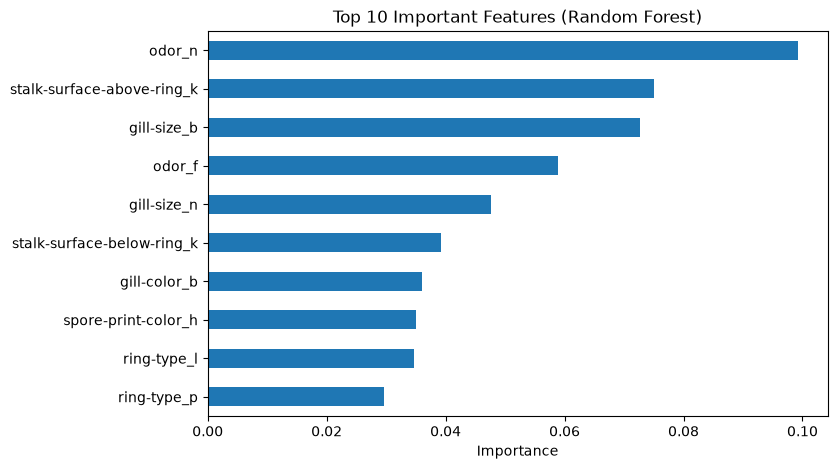

In [24]:
# importance of each feature in the random forest
importance = pd.Series(rf_model.feature_importances_, index=X.columns)
top10 = importance.sort_values(ascending=False).head(10)

print(top10.round(4))

plt.figure(figsize=(8, 5))
top10.plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Top 10 Important Features (Random Forest)")
plt.xlabel("Importance")
plt.show()

In [25]:
print("Decision Tree  -> Accuracy:", round(dt_acc, 4), "| Recall:", round(dt_rec, 4), "| F1:", round(dt_f1, 4))
print("Random Forest  -> Accuracy:", round(rf_acc, 4), "| Recall:", round(rf_rec, 4), "| F1:", round(rf_f1, 4))
print("Most important feature:", top10.index[0])

Decision Tree  -> Accuracy: 1.0 | Recall: 1.0 | F1: 1.0
Random Forest  -> Accuracy: 1.0 | Recall: 1.0 | F1: 1.0
Most important feature: odor_n
